# Pesquisa Informada — Greedy Best-First Search e A\*

**Inteligência Artificial 2026/27 — Grupo G05**

A pesquisa informada usa uma **heurística** (uma estimativa de quanto falta) para escolher que estado explorar a seguir. Neste notebook:

- **Greedy Best-First Search** — escolhe sempre o estado que *parece* mais perto do fim (só olha para a heurística). É rápido, mas não garante a melhor solução.
- **A\*** — escolhe o estado com menor custo já feito + estimativa do que falta (`f = g + h`). Com uma heurística admissível garante a solução ótima. Garante o ótimo, mas tem de explorar muitos mais estados; a secção 8 mostra o que acontece neste problema.

Como pede o enunciado, cada algoritmo usa **duas heurísticas**, mostram-se as **rotas dos 2 veículos do tiny** e conta-se o número de **nós expandidos**.

O código está em `src/informed.py`.

## 1. Preparação

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt

# Pasta principal do projeto (funciona a partir da raiz ou da pasta notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.model import Problem, check_solution, print_solution
from src.informed import (greedy_search, heuristica1, heuristica2,
                          sucessores, estado_viavel, terminou)

problemas = {nome: Problem.from_csv(RAIZ / nome) for nome in ["data_tiny", "data_small"]}
heuristicas = {"H1": heuristica1, "H2": heuristica2}
for nome, p in problemas.items():
    print(f"{nome}: {len(p.orders)} encomendas, {len(p.requests)} itens, {len(p.vehicles)} veículos")

data_tiny: 12 encomendas, 40 itens, 2 veículos
data_small: 25 encomendas, 80 itens, 2 veículos


## 2. O problema como pesquisa

| Elemento | No nosso problema |
|---|---|
| **Estado** | "fotografia" do momento: onde está cada veículo, a que horas fica livre, quanto leva, e em que fase está cada item (no produtor, no veículo, no armazém, carregado ou entregue) |
| **Estado inicial** | veículos vazios no armazém, todos os itens nos produtores |
| **Ações (sucessores)** | uma paragem de um veículo: recolher um grupo de itens num produtor, descarregar no armazém, carregar ou entregar uma encomenda inteira |
| **Teste de fim** | todos os itens entregues |
| **Custo** | km percorridos (incluindo o regresso ao armazém) |

Cada ação é verificada pelo `apply_stop` do `model.py` (janelas de tempo, capacidade, 24h no armazém, horizonte). Além disso, o Greedy deita fora os **becos sem saída** (`estado_viavel`): estados em que, mesmo no melhor cenário, já não se consegue recolher ou entregar algo a tempo.

Exemplo: os movimentos possíveis a partir do estado inicial do tiny.

In [2]:
p = problemas["data_tiny"]
inicial = p.initial_state()

linhas = []
for novo, veiculo, operacao, ids in sucessores(p, inicial):
    linhas.append({"Veículo": veiculo, "Operação": operacao,
                   "Local": p.name(p.place_of(operacao, p.request[ids[0]])),
                   "Itens": ids, "km": round(novo.km, 1),
                   "Viável": estado_viavel(p, novo)})
print("Estado inicial é final?", terminou(p, inicial))
pd.DataFrame(linhas)

Estado inicial é final? False


,Veículo,Operação,Local,Itens,km,Viável
0,1,pickup,Campos Leite,"(12, 23, 27, 28, 30, 33, 36, 38, 39)",37.7,True
1,1,pickup,Hortas Valente,"(5, 13, 25, 31, 32, 34, 37, 40)",30.6,True
2,1,pickup,Horta Morais,"(6, 11, 22, 24, 26, 29, 35)",29.1,True
3,1,pickup,Horta Morais,"(3, 4, 8, 9, 14, 17)",29.1,True
4,1,pickup,Campos Leite,"(1, 7, 15, 16, 18)",37.7,True
5,1,pickup,Hortas Valente,"(2, 10, 19, 20, 21)",30.6,True
6,2,pickup,Campos Leite,"(12, 23, 27, 28, 30, 33, 36, 38, 39)",37.7,True
7,2,pickup,Hortas Valente,"(5, 13, 25, 31, 32, 34, 37, 40)",30.6,True
8,2,pickup,Horta Morais,"(6, 11, 22, 24, 26, 29, 35)",29.1,True
9,2,pickup,Horta Morais,"(3, 4, 8, 9, 14, 17)",29.1,True


## 3. Heurísticas

- **H1 — operações que faltam:** cada item faz 4 operações (recolher, descarregar, carregar, entregar); H1 conta quantas ainda faltam. Menos é melhor.
- **H2 — locais que faltam visitar:** conta quantos produtores e clientes ainda é preciso visitar; em caso de empate, desempata pelos km desses locais ao armazém e, por fim, pela H1.

No Greedy as heurísticas não precisam de ser admissíveis (não garantem o ótimo): servem só para guiar a pesquisa.

In [3]:
for nome, h in heuristicas.items():
    print(f"{nome} no estado inicial do tiny:", h(p, inicial))

H1 no estado inicial do tiny: 160
H2 no estado inicial do tiny: (8, 220.68, 160)


## 4. O algoritmo Greedy

Igual ao do notebook do professor, adaptado ao problema:

1. Uma **fila de prioridade** (`heapq`) ordenada pela heurística.
2. Tira o estado com **menor heurística**; se já foi visitado, ignora-o.
3. Se é final, confirma a solução com o `check_solution` e devolve-a.
4. Senão, gera os sucessores, deita fora os becos sem saída e põe os restantes na fila.

**Decisões para ser rápido:**
- Só se consideram as **3 encomendas mais urgentes** para carregar e para entregar, e poucos grupos de recolha por produtor.
- **Janela de 2 horas:** numa primeira passagem, só se expandem movimentos que começam até 2 horas depois do movimento mais cedo possível. Se não houver solução, faz-se uma segunda passagem sem esta janela.
- No máximo **5000 expansões** por passagem.

## 5. Resultados

Rotas para os veículos do tiny e do small, com as duas heurísticas.

In [4]:
solucoes = {}
linhas = []
for nome, prob in problemas.items():
    for h_nome, h in heuristicas.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(prob, prob.initial_state(), h)
        tempo = time.perf_counter() - inicio
        valida, km, mensagem = check_solution(prob, solucao)
        solucoes[(nome, h_nome)] = solucao
        linhas.append({"Dataset": nome, "Heurística": h_nome, "Solução válida": valida,
                       "Distância (km)": km, "Nós expandidos": nos, "Tempo (s)": round(tempo, 2)})
resultados_greedy = pd.DataFrame(linhas)
resultados_greedy

,Dataset,Heurística,Solução válida,Distância (km),Nós expandidos,Tempo (s)
0,data_tiny,H1,True,798.54,502,1.40
1,data_tiny,H2,True,802.24,34,0.09
2,data_small,H1,True,1070.60,914,4.51
3,data_small,H2,True,1009.19,1333,13.30


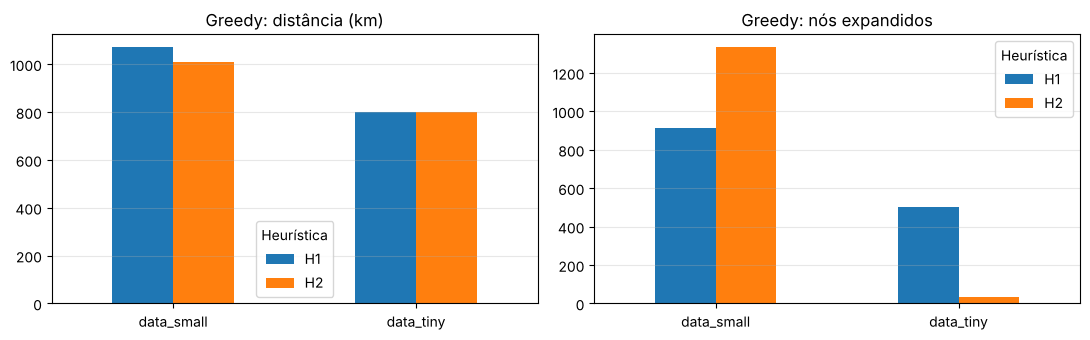

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
for eixo, coluna in zip(eixos, ["Distância (km)", "Nós expandidos"]):
    tabela = resultados_greedy.pivot(index="Dataset", columns="Heurística", values=coluna)
    tabela.plot(kind="bar", ax=eixo, rot=0)
    eixo.set_title(f"Greedy: {coluna.lower()}")
    eixo.set_xlabel("")
    eixo.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Rotas dos 2 veículos do tiny (melhor heurística)

In [6]:
nome = "data_tiny"
melhor = min(heuristicas, key=lambda h: check_solution(problemas[nome], solucoes[(nome, h)])[1])
print(f"Greedy com {melhor}\n")
print_solution(problemas[nome], solucoes[(nome, melhor)])

Greedy com H1

Solução válida | total: 798.54 km

Veículo 1 (capacidade 150 kg)
  30/10 09:00  pickup   Campos Leite                 [12, 23, 27, 28, 30, 33, 36, 38, 39] +37.7 km
  30/10 09:41  pickup   Hortas Valente               [5, 13, 25, 31, 32, 34, 37, 40] +23.6 km
  30/10 10:32  unload   Centro de Recolha 1          [5, 12, 13, 23, 25, 27, 28, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40] +30.6 km
  30/10 10:47  load     Centro de Recolha 1          [32, 33, 34, 35, 36, 37, 38, 39, 40, 25, 26, 27, 28, 29] +0.0 km
  30/10 12:15  deliver  Casa 2                       [36, 37, 38, 39, 40]     +36.1 km
  30/10 13:36  deliver  Loja 1                       [32, 33, 34, 35]         +53.7 km
  30/10 14:11  load     Centro de Recolha 1          [5, 6]                   +18.8 km
  31/10 07:45  pickup   Horta Morais                 [3, 4, 8, 9, 14, 17]     +29.1 km
  31/10 08:33  unload   Centro de Recolha 1          [3, 4, 8, 9, 14, 17]     +29.1 km
  31/10 09:20  deliver  Loja 5              

## 6. Efeito da janela de 2 horas

Para justificar a janela de 2 horas, corre-se o Greedy **sem janela** (só a passagem completa, com o mesmo limite de 5000 expansões).

In [7]:
linhas = []
for nome, prob in problemas.items():
    for h_nome, h in heuristicas.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(prob, prob.initial_state(), h, janela_horas=None)
        tempo = time.perf_counter() - inicio
        com_janela = resultados_greedy[(resultados_greedy["Dataset"] == nome)
                                       & (resultados_greedy["Heurística"] == h_nome)].iloc[0]
        linhas.append({"Dataset": nome, "Heurística": h_nome,
                       "Com janela (km)": com_janela["Distância (km)"],
                       "Com janela (nós)": com_janela["Nós expandidos"],
                       "Sem janela (km)": check_solution(prob, solucao)[1] if solucao else "sem solução",
                       "Sem janela (nós)": nos, "Sem janela (s)": round(tempo, 1)})
pd.DataFrame(linhas)

,Dataset,Heurística,Com janela (km),Com janela (nós),Sem janela (km),Sem janela (nós),Sem janela (s)
0,data_tiny,H1,798.54,502,864.03,2469,8.8
1,data_tiny,H2,802.24,34,sem solução,5000,15.4
2,data_small,H1,1070.60,914,sem solução,5000,24.7
3,data_small,H2,1009.19,1333,sem solução,5000,25.7


## 7. Análise do Greedy

**Encontra sempre uma solução válida, e depressa.** Nos dois datasets e com as duas heurísticas, o Greedy encontra rotas que cumprem todas as restrições.

**H1 vs H2.**
- No **tiny**, as duas dão soluções parecidas (798,54 e 802,24 km), mas a H2 precisa de muito menos nós (34 contra 502). Contar os locais que faltam visitar orienta melhor a pesquisa do que contar operações.
- No **small**, a H2 dá a melhor solução (1009,19 contra 1070,60 km), mas expande mais nós (1333 contra 914). A H2 tem muitos estados com o mesmo valor (o número de locais só desce quando o último item de um produtor é recolhido ou a última encomenda de um cliente é entregue), e o Greedy explora vários antes de encontrar um que a faça descer.

**A janela de 2 horas é essencial.** Sem ela, o Greedy dá uma solução pior no tiny com a H1 (864,03 contra 798,54 km, com quase 5 vezes mais nós) e, nos outros casos, não encontra solução em 5000 expansões. Sem janela, o Greedy "salta" para tarefas muito à frente no tempo (por exemplo, recolhas do dia seguinte) e deixa por fazer tarefas urgentes, que depois já não cabem nas janelas.

**Limitações.** O Greedy não garante a melhor solução: o Hill-Climbing (notebook `local_search.ipynb`) melhora estas soluções em 11% a 21%. Os limites usados para ser rápido (as 3 encomendas mais urgentes, poucos grupos de recolha e a janela de 2 horas) deixam de fora algumas combinações; em contrapartida, sem eles a pesquisa fica muito mais lenta.

## 8. A\*

O A\* escolhe sempre o estado com menor `f = g + h`:
- `g` = km já percorridos (custo real até aqui);
- `h` = estimativa dos km que ainda faltam.

Se a heurística for **admissível** (nunca exagera o que falta) e o teste de fim for feito quando o estado **sai** da fila, a primeira solução que o A\* devolve é a **ótima**. Em troca, tem de explorar todos os estados que ainda possam dar uma solução mais barata.

O código está em `a_star_search`, em `src/informed.py`, e resolve o **problema completo** (sem retirar nenhuma regra).

### 8.1 Formulação

| Elemento | No A\* |
|---|---|
| **Estado** | o mesmo do Greedy (`State` do `model.py`, com horas, cargas e fase de cada item) |
| **Sucessores** | **todos** os movimentos elementares: recolher um item, descarregar um item, carregar ou entregar uma encomenda completa. Repetir a operação no mesmo local junta-a à paragem anterior. Sem os cortes do Greedy (3 mais urgentes, janela de 2 h), por isso, se chegasse ao fim, a solução seria mesmo a **ótima** |
| **Regras** | verificadas pelo `apply_stop` (janelas, capacidade, 24 h, horizonte) |
| **Poda** | `estado_viavel` do Greedy: só elimina estados que, mesmo no melhor cenário, já não cumprem uma janela — não estraga o ótimo |
| **Custo (`g`)** | km percorridos, incluindo o regresso ao armazém |

**Heurísticas (ambas admissíveis, em km, com as distâncias mínimas de Floyd-Warshall):**
- **H1 — regresso:** soma da distância de cada veículo ao armazém. Todos têm de voltar, por isso nunca é mais do que falta.
- **H2 — tarefa mais cara:** para cada produtor por visitar, algum veículo tem de lá ir e voltar ao armazém; para cada encomenda por entregar, algum veículo tem de ir ao cliente (passando pelo armazém, se ainda não a leva) e voltar. Fica com a tarefa mais cara, mais o regresso dos outros veículos. Nunca é menor do que a H1.

**O algoritmo**:
1. Fila de prioridade (`heapq`) ordenada por `f = g + h`.
2. Tira o estado com menor `f`; se já há um caminho mais barato para ele (`best_g`), ignora-o.
3. Se é final, confirma com o `check_solution` e devolve-o — o teste é feito quando o estado sai da fila, o que garante o ótimo.
4. Senão, gera os sucessores, deita fora os becos sem saída e guarda os que melhoram o `best_g`.

### 8.2 Resultados

Corremos com 500 expansões e pedimos as **estatísticas** da pesquisa:

In [8]:
from src.informed import a_star_search, astar_h1, astar_h2

linhas = []
for nome, prob in problemas.items():
    for h_nome, h in {"H1": astar_h1, "H2": astar_h2}.items():
        rotas, nos, info = a_star_search(prob, heuristica=h, max_expansoes=500, estatisticas=True)
        fases = info["estado mais avançado"]
        linhas.append({"Dataset": nome, "Heurística": h_nome,
                       "Solução": "encontrada" if rotas else "sem solução",
                       "Expandidos": nos, "Gerados": info["gerados"],
                       "Repetidos": info["repetidos"], "Ainda na fila": info["ainda na fila"],
                       "Gerados por expansão": round(info["gerados"] / nos),
                       "Mais avançado: recolhidos": len(prob.requests) - fases["por recolher"],
                       "Mais avançado: entregues": fases["entregues"],
                       "Tempo (s)": info["tempo (s)"]})
resultados_astar = pd.DataFrame(linhas)
resultados_astar

,Dataset,Heurística,Solução,Expandidos,Gerados,Repetidos,Ainda na fila,Gerados por expansão,Mais avançado: recolhidos,Mais avançado: entregues,Tempo (s)
0,data_tiny,H1,sem solução,500,21355,1127,20855,43,3,0,10.65
1,data_tiny,H2,sem solução,500,20247,1460,19747,40,3,0,11.20
2,data_small,H1,sem solução,500,40914,2840,40414,82,3,0,41.54
3,data_small,H2,sem solução,500,40914,2840,40414,82,3,0,42.78


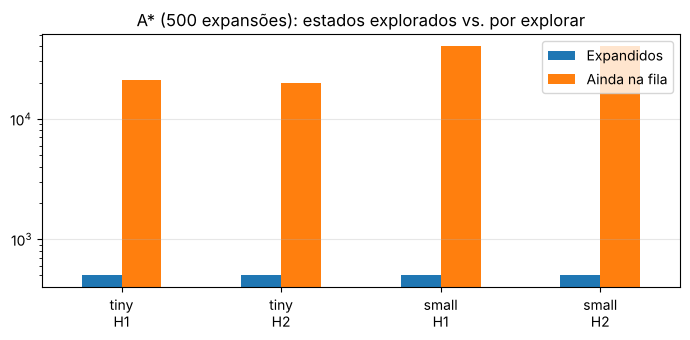

In [9]:
fig, eixo = plt.subplots(figsize=(7, 3.5))
tabela = resultados_astar.set_index(["Dataset", "Heurística"])[["Expandidos", "Ainda na fila"]]
tabela.plot(kind="bar", ax=eixo, rot=0, logy=True)
eixo.set_title("A* (500 expansões): estados explorados vs. por explorar")
eixo.set_xticklabels([f"{d.replace('data_', '')}\n{h}" for d, h in tabela.index])
eixo.set_xlabel("")
eixo.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8.3 Porque não encontra solução?

- **A fila cresce muito mais depressa do que a pesquisa avança.** Cada estado expandido gera dezenas de estados novos (coluna "Gerados por expansão"): há um sucessor por cada item que se pode recolher, por cada item que se pode descarregar e por cada encomenda, para cada veículo. Depois de 500 expansões ficam dezenas de milhares de estados por explorar.
- **O A\* espalha-se em largura.** Expande sempre o menor `f`, e os estados do início (poucas operações, poucos km) têm quase sempre `f` menor do que os mais avançados. Por isso o estado mais avançado explorado tem apenas **3 itens recolhidos e nenhum entregue** — longe dos 40 (tiny) ou 80 (small) itens.
- **As horas fazem quase todos os estados diferentes.** O mesmo conjunto de operações feito por outra ordem dá horas diferentes, e portanto estados diferentes; o `best_g` quase nunca os junta (a coluna "Repetidos" é pequena comparada com "Gerados").

No small, as duas heurísticas dão exatamente os mesmos números: nestes primeiros 500 estados ordenam a fila da mesma maneira.

Aumentar o limite não resolve: o número de estados cresce muito mais depressa do que o tempo disponível.

### 8.4 Comparação com o Greedy

Como o A\* não tem solução, **não se podem comparar os km**. Compara-se antes o **comportamento da pesquisa**: com um número de expansões parecido, até onde chega cada algoritmo?

In [10]:
linhas = []
for nome, prob in problemas.items():
    total_itens = len(prob.requests)
    for _, r in resultados_greedy[resultados_greedy["Dataset"] == nome].iterrows():
        linhas.append({"Dataset": nome, "Algoritmo": f"Greedy {r['Heurística']}",
                       "Expansões": r["Nós expandidos"],
                       "Itens entregues": f"{total_itens} / {total_itens}",
                       "Solução válida": "sim", "Distância (km)": r["Distância (km)"],
                       "Tempo (s)": r["Tempo (s)"]})
    for _, r in resultados_astar[resultados_astar["Dataset"] == nome].iterrows():
        linhas.append({"Dataset": nome, "Algoritmo": f"A* {r['Heurística']}",
                       "Expansões": r["Expandidos"],
                       "Itens entregues": f"{r['Mais avançado: entregues']} / {total_itens}",
                       "Solução válida": "não encontrada", "Distância (km)": "—",
                       "Tempo (s)": r["Tempo (s)"]})
pd.DataFrame(linhas)

,Dataset,Algoritmo,Expansões,Itens entregues,Solução válida,Distância (km),Tempo (s)
0,data_tiny,Greedy H1,502,40 / 40,sim,798.54,1.40
1,data_tiny,Greedy H2,34,40 / 40,sim,802.24,0.09
2,data_tiny,A* H1,500,0 / 40,não encontrada,—,10.65
3,data_tiny,A* H2,500,0 / 40,não encontrada,—,11.20
4,data_small,Greedy H1,914,80 / 80,sim,1070.6,4.51
5,data_small,Greedy H2,1333,80 / 80,sim,1009.19,13.30
6,data_small,A* H1,500,0 / 80,não encontrada,—,41.54
7,data_small,A* H2,500,0 / 80,não encontrada,—,42.78


**Leitura da tabela:**
- Com **34 a 1333 expansões**, o Greedy entrega **todos** os itens e devolve uma solução válida.
- Com **500 expansões**, o A\* ainda **não entregou nenhum item**.

A diferença está em como cada um escolhe o próximo estado:
- O **Greedy** usa só `h` (o que falta). Cada operação feita faz `h` descer, por isso vai sempre "em profundidade" — cada expansão avança uma operação, até ao fim.
- O **A\*** usa `g + h`. Cada operação feita aumenta `g` (mais km), por isso os estados mais avançados ficam para trás na fila e ele volta sempre aos estados do início — avança "em largura".

Além disso, o Greedy considera poucos sucessores por estado (cortes para ser rápido) e o A\* considera todos, para não perder a garantia de ótimo.

## 9. Conclusão: Greedy vs A\*

| | Greedy | A\* |
|---|---|---|
| Escolhe o estado com menor | `h` | `g + h` |
| Heurísticas | não precisam de ser admissíveis (H1: operações; H2: locais) | admissíveis, em km (H1: regresso; H2: tarefa mais cara) |
| Sucessores | poucos (3 encomendas mais urgentes, janela de 2 h) | todos os movimentos elementares |
| Garante o ótimo | não | sim, se chegasse ao fim |
| Nos nossos dados | solução válida em todos os casos, em segundos | sem solução no limite de expansões |

- O **Greedy** é o algoritmo que resolve o problema: rápido e sempre com rotas válidas, mas sem garantia de ser o melhor (o Hill-Climbing, no notebook `local_search.ipynb`, melhora estas soluções).
- O **A\*** está implementado corretamente (heurísticas admissíveis, `best_g`, teste de fim à saída da fila), mas **não é viável neste problema**: o espaço de estados com horas é demasiado grande e a pesquisa espalha-se em largura sem chegar ao fim.
- É o compromisso clássico da pesquisa informada: **o Greedy troca a garantia de ótimo pela rapidez; o A\* garante o ótimo, mas paga com o número de estados que tem de explorar.**